# RDKit exercise solution

In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools, Descriptors


1) Load the data. Pay attention to relative paths.

In [2]:
df = pd.read_csv("data/delaney.csv")
df.head()

,Compound ID,logS,smiles
0,"1,1,1,2-Tetrachloroethane",-2.18,ClCC(Cl)(Cl)Cl
1,"1,1,1-Trichloroethane",-2.00,CC(Cl)(Cl)Cl
2,"1,1,2,2-Tetrachloroethane",-1.74,ClC(Cl)C(Cl)Cl
3,"1,1,2-Trichloroethane",-1.48,ClCC(Cl)Cl
4,"1,1,2-Trichlorotrifluoroethane",-3.04,FC(F)(Cl)C(F)(Cl)Cl


Get an overview about the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Compound ID  1144 non-null   str    
 1   logS         1144 non-null   float64
 2   smiles       1144 non-null   str    
dtypes: float64(1), str(2)
memory usage: 67.4 KB


Clean up (exemplary)

In [4]:
# all following operations need SMILES ad logS, hence drop where SMILES and logS are missing
df.dropna(subset=["smiles", "logS"], inplace=True)

# note that this could also be done reusably: e.g. define a TARGET = "logS" in the beginning

Add a column with images of your sturctures to the dataframe (Hint: Use RdKit's `PandasTools`)

In [5]:
def prep_df(df):
    df["mol"] = df["smiles"].apply(lambda s: Chem.MolFromSmiles(s))
    PandasTools.RenderImagesInAllDataFrames(images=True)
    PandasTools.AddMoleculeColumnToFrame(df, smilesCol="smiles", molCol="mol")
    return df


,Compound ID,logS,smiles,mol
0,"1,1,1,2-Tetrachloroethane",-2.18,ClCC(Cl)(Cl)Cl,
1,"1,1,1-Trichloroethane",-2.00,CC(Cl)(Cl)Cl,
2,"1,1,2,2-Tetrachloroethane",-1.74,ClC(Cl)C(Cl)Cl,
3,"1,1,2-Trichloroethane",-1.48,ClCC(Cl)Cl,
4,"1,1,2-Trichlorotrifluoroethane",-3.04,FC(F)(Cl)C(F)(Cl)Cl,

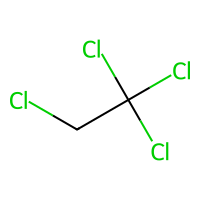
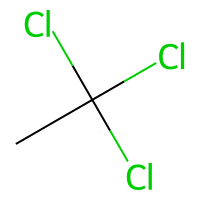
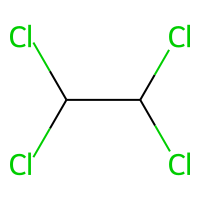
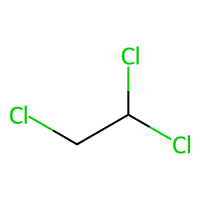
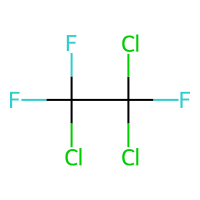

In [6]:
prep_df(df)
df.head()

3) Create your own fingerprint system: Write a function that uses SMARTS in a substructure search to assess if a certain motif (e.g. aromatic ring, ketone, carbon chain longer than 3 C, double bonds, etc) is present which you believe is important. The resulting Boolean should be saved in a list (i.e. your custom fingerprint). Look for 10 motifs and append this list of binary values. In the end, your fingerprint should look something like this: `[0, 0, 1, 1, 1, 0, 1, 0, 1, 0]`, with each value representing a certain molecular functional group / motif.

In [7]:
def my_fp(smiles):
    # define substructures for fingerprint: 
    # aromatic compounds, aromatic nitrogens, carboxylic acids/esters, halogens, 
    # amines with at least one H, at least one carbon chain of 4 C, a quaternary C,
    # alcohols, any atom in a ring, thiols
    mol = Chem.MolFromSmiles(smiles)
    my_fp = []
    substructures = ["[a]", 
                     "[n]", 
                     "[CX3](=O)[OX2]", 
                     "[F,Cl,Br,I]", 
                     "[NX3H1]", 
                     "CCCC", 
                     "[CX4H0]",
                     "[CX4][OX2H1]",
                     "[R]",
                     "[SX2H1]"
                     ]
    for smarts in substructures:
        query_mol = Chem.MolFromSmarts(smarts)
        if mol.HasSubstructMatch(query_mol):
            my_fp.append(1)
        else:
            my_fp.append(0)

    return my_fp

,Compound ID,logS,smiles,mol,myFP
0,"1,1,1,2-Tetrachloroethane",-2.18,ClCC(Cl)(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 1, 0, 0, 0]"
1,"1,1,1-Trichloroethane",-2.00,CC(Cl)(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 1, 0, 0, 0]"
2,"1,1,2,2-Tetrachloroethane",-1.74,ClC(Cl)C(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]"
3,"1,1,2-Trichloroethane",-1.48,ClCC(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]"
4,"1,1,2-Trichlorotrifluoroethane",-3.04,FC(F)(Cl)C(F)(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 1, 0, 0, 0]"

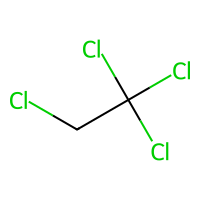
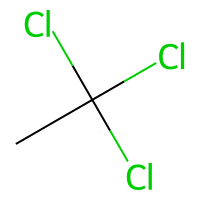
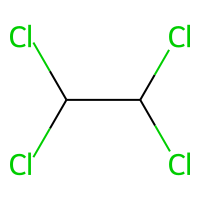
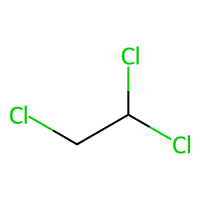
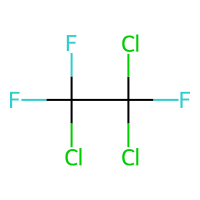

In [8]:
df["myFP"] = df["smiles"].apply(my_fp)
df.head()

5) Create Morgan fingerprints as spearate feature (e.g. as column in your df).

,Compound ID,logS,smiles,mol,myFP,MorganFP
0,"1,1,1,2-Tetrachloroethane",-2.18,ClCC(Cl)(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 1, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,"1,1,1-Trichloroethane",-2.00,CC(Cl)(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 1, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,"1,1,2,2-Tetrachloroethane",-1.74,ClC(Cl)C(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,"1,1,2-Trichloroethane",-1.48,ClCC(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]","[0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,"1,1,2-Trichlorotrifluoroethane",-3.04,FC(F)(Cl)C(F)(Cl)Cl,,"[0, 0, 0, 1, 0, 0, 1, 0, 0, 0]","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."

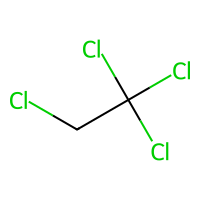
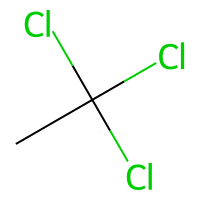
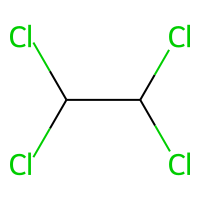
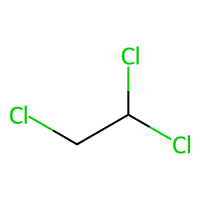
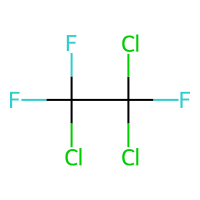

In [9]:
from rdkit.Chem import rdFingerprintGenerator

def mol2fp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2,fpSize=1024)
    fp = mfpgen.GetFingerprint(mol)
    return fp

df["MorganFP"] = df["smiles"].apply(mol2fp)
df.head()

6) Calculate all physical descriptors available in RDKit and add them to a new dataframe (hint: `Descriptors.CalcMolDescriptors` returns a dictionary of all available descriptors)

In [10]:
def calculate_descriptors(df):
    desc_df = pd.DataFrame([Descriptors.CalcMolDescriptors(m) for m in df["mol"]], 
                           index=df.index,)
    return desc_df

In [11]:
desc_df = calculate_descriptors(df)
desc_df.head()

,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,5.116512,5.116512,0.039352,-1.276235,0.487138,12.00,167.850,165.834,165.891061,38,...,0,0,0,0,0,0,0,0,0,0
1,5.060957,5.060957,1.083333,-1.083333,0.445171,12.00,133.405,130.381,131.930033,32,...,0,0,0,0,0,0,0,0,0,0
2,5.114198,5.114198,0.672840,-0.672840,0.527312,11.00,167.850,165.834,165.891061,38,...,0,0,0,0,0,0,0,0,0,0
3,5.095679,5.095679,0.308642,-0.405864,0.480258,9.60,133.405,130.381,131.930033,32,...,0,0,0,0,0,0,0,0,0,0
4,11.544753,11.544753,3.685957,-4.226080,0.553756,14.25,187.375,187.375,185.901768,50,...,0,0,0,0,0,0,0,0,0,0


On reusability: combine descriptor functions into one

In [12]:
def prep_features(df):
    df["myFP"] = df["smiles"].apply(my_fp)
    df["MorganFP"] = df["smiles"].apply(mol2fp)
    desc_df = calculate_descriptors(df)
    print("\n Calculated fingerprints and descriptors!")
    print(desc_df.info())
    print(df.info())
    return df, desc_df

In [13]:
df, desc_df = prep_features(df)


 Calculated fingerprints and descriptors!
<class 'pandas.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Columns: 217 entries, MaxAbsEStateIndex to fr_urea
dtypes: float64(107), int64(110)
memory usage: 1.9 MB
None
<class 'pandas.DataFrame'>
RangeIndex: 1144 entries, 0 to 1143
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Compound ID  1144 non-null   str    
 1   logS         1144 non-null   float64
 2   smiles       1144 non-null   str    
 3   mol          1144 non-null   object 
 4   myFP         1144 non-null   object 
 5   MorganFP     1144 non-null   object 
dtypes: float64(1), object(3), str(2)
memory usage: 94.2+ KB
None


7) Use a Random Forest Regressor to predict the target to compare:
- your custom fingerprint,
- the Morgan fingerprints,
- the physical descriptors.

In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

def rf_assessment(X,y):
# X = np.vstack(df["myFP"])              
# y = df["logS"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(n_estimators=200, random_state=42)
    rf.fit(X_train, y_train)

    pred_train = rf.predict(X_train)
    pred_test = rf.predict(X_test)

    print("Train R2:", r2_score(y_train, pred_train))
    print("Test  R2:", r2_score(y_test, pred_test))
    print("Test RMSE:", mean_squared_error(y_test, pred_test) ** 0.5)
    print("Test MAE:", mean_absolute_error(y_test, pred_test))

    return # optionally, metrics could be returned

Custom FP:

In [15]:
X = np.vstack(df["myFP"])              
y = df["logS"]

rf_assessment(X, y)

Train R2: 0.409391440927541
Test  R2: 0.3678495208668341
Test RMSE: 1.6591341564391253
Test MAE: 1.2509049476116132


Morgan FP:

In [16]:
X = np.vstack(df["MorganFP"])              
y = df["logS"]

rf_assessment(X, y)

Train R2: 0.9412076656507028
Test  R2: 0.677487038437718
Test RMSE: 1.1850723221734931
Test MAE: 0.8886460608442986


Descriptors:

In [17]:
X = desc_df               
y = df["logS"]

rf_assessment(X, y)

Train R2: 0.9865213445364112
Test  R2: 0.9099577890472579
Test RMSE: 0.6261730091748434
Test MAE: 0.45846544739031003


8) Repeat for the second dataset - focus on reusable code / functions, so that you can use them for both datasets. Compare the results for the two datasets and discuss!

In [26]:
# Input parameters for reusing functions

CSV_FILE = "data/ecoli_mics_filtered.csv"
TARGET = "mic" # Note that for now there is still no exception handling included, if the target is not contained in df.columns
SIZE = 7000 # set arbitrary sample size
RANDOMSEED = 42
SMILES_COL = "smiles" # same as for TARGET

In [27]:
def load_data(csv_file=CSV_FILE, size=SIZE, seed=RANDOMSEED):
    """Loads data from csv (default location set in input parameter CSV_FILE) as dataframe; 
    compares the lenght of the dataframe to a preset SIZE and takes a randomsample of the preset SIZE.
    Prints df.info() and returns the df."""
    df = pd.read_csv(csv_file)
    if df.size > size:
        df = df.sample(size, random_state=seed)
    print(f"\n Loaded data from {csv_file}, decreased size to {size}.")
    print(df.info())
    return df

In [28]:
def clean_data(df, smiles=SMILES_COL, target=TARGET):
    df.dropna(subset=[smiles, target], inplace=True)
    print(f"\n SMILES and {target} needed for calculations - dropped all rows with NaNs in either of them.")
    return df

Reuse all previous functions to repeat procedure for second / any dataframe:

In [29]:
df = load_data()


 Loaded data from data/ecoli_mics_filtered.csv, decreased size to 7000.
<class 'pandas.DataFrame'>
Index: 7000 entries, 8235 to 57143
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   chembl_id  7000 non-null   str    
 1   smiles     6996 non-null   str    
 2   mic        6986 non-null   float64
 3   unit       7000 non-null   str    
dtypes: float64(1), str(3)
memory usage: 807.9 KB
None


In [30]:
clean_data(df)


 SMILES and mic needed for calculations - dropped all rows with NaNs in either of them.


,chembl_id,smiles,mic,unit
8235,CHEMBL4171739,C=C(/C=N/O)[C@]1(OC)C[C@@]2(C)C(=CC1=O)C=C[C@H...,100.0,ug.mL-1
20217,CHEMBL1436,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)O)=C(COC(N)...,256.0,ug.mL-1
50897,CHEMBL5431787,Nc1nc(N)c2c(ccc3c2ccn3Cc2nc3ccc(C(=O)O)cc3s2)n1,8.0,ug.mL-1
28431,CHEMBL3244617,COn1cc(C(=O)O)c(=O)c2c3c(ccc21)OCC3,100.0,ug.mL-1
23847,CHEMBL996,CO[C@@]1(NC(=O)Cc2cccs2)C(=O)N2C(C(=O)O)=C(COC...,8.0,ug.mL-1
...,...,...,...,...
36194,CHEMBL3125566,CCOc1cccc(CC(=O)Nc2nc(-c3ccccc3)cs2)c1,50.0,ug.mL-1
7208,CHEMBL2088957,O=C1NC(=S)NC(=O)C1=Cc1ccc(/C=C/C(=O)c2ccccc2F)cc1,64.0,ug.mL-1
45477,CHEMBL3361293,CCOc1ccc2[nH]c3c(c2c1)C[C@]1(C)[C@H]2CC=C4[C@@...,100.0,ug.mL-1
41319,CHEMBL1210158,Cc1ccc(/C=N/NC(=O)c2ccc(-c3nc4ccccc4[nH]3)cc2)cc1,25.0,ug.mL-1


,chembl_id,smiles,mic,unit,mol
8235,CHEMBL4171739,C=C(/C=N/O)[C@]1(OC)C[C@@]2(C)C(=CC1=O)C=C[C@H...,100.0,ug.mL-1,
20217,CHEMBL1436,CO/N=C(\C(=O)N[C@@H]1C(=O)N2C(C(=O)O)=C(COC(N)...,256.0,ug.mL-1,
50897,CHEMBL5431787,Nc1nc(N)c2c(ccc3c2ccn3Cc2nc3ccc(C(=O)O)cc3s2)n1,8.0,ug.mL-1,
28431,CHEMBL3244617,COn1cc(C(=O)O)c(=O)c2c3c(ccc21)OCC3,100.0,ug.mL-1,
23847,CHEMBL996,CO[C@@]1(NC(=O)Cc2cccs2)C(=O)N2C(C(=O)O)=C(COC...,8.0,ug.mL-1,
...,...,...,...,...,...
36194,CHEMBL3125566,CCOc1cccc(CC(=O)Nc2nc(-c3ccccc3)cs2)c1,50.0,ug.mL-1,
7208,CHEMBL2088957,O=C1NC(=S)NC(=O)C1=Cc1ccc(/C=C/C(=O)c2ccccc2F)cc1,64.0,ug.mL-1,
45477,CHEMBL3361293,CCOc1ccc2[nH]c3c(c2c1)C[C@]1(C)[C@H]2CC=C4[C@@...,100.0,ug.mL-1,
41319,CHEMBL1210158,Cc1ccc(/C=N/NC(=O)c2ccc(-c3nc4ccccc4[nH]3)cc2)cc1,25.0,ug.mL-1,

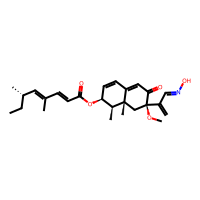
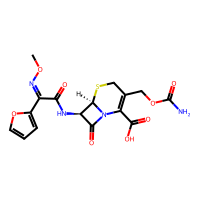
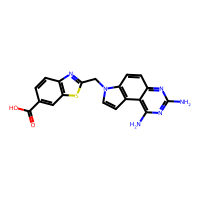
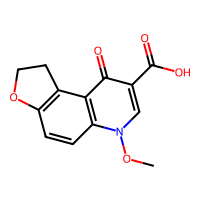
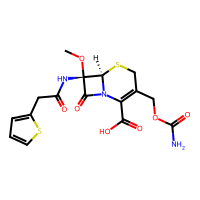
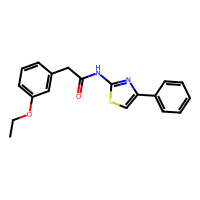
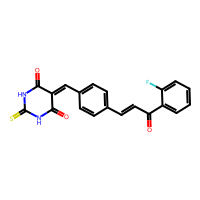
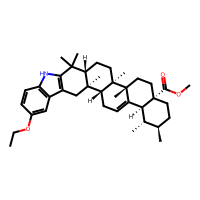
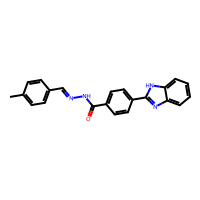
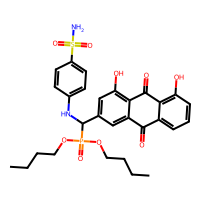

In [31]:

prep_df(df)

In [32]:
df, desc_df = prep_features(df)


 Calculated fingerprints and descriptors!
<class 'pandas.DataFrame'>
Index: 6982 entries, 8235 to 57143
Columns: 217 entries, MaxAbsEStateIndex to fr_urea
dtypes: float64(107), int64(110)
memory usage: 11.6 MB
None
<class 'pandas.DataFrame'>
Index: 6982 entries, 8235 to 57143
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   chembl_id  6982 non-null   str    
 1   smiles     6982 non-null   str    
 2   mic        6982 non-null   float64
 3   unit       6982 non-null   str    
 4   mol        6982 non-null   object 
 5   myFP       6982 non-null   object 
 6   MorganFP   6982 non-null   object 
dtypes: float64(1), object(3), str(3)
memory usage: 969.8+ KB
None


Run comparison with RF model:

In [33]:
X_dict = {"Custom FP": np.vstack(df["myFP"]), 
          "Morgan FP": np.vstack(df["MorganFP"]),
          "Descriptors": desc_df}
y = df[TARGET]

for key, X in X_dict.items():
    print(f"RF assessment for {key}:")
    rf_assessment(X, y)
    print("------------------------------------------\n")

RF assessment for Custom FP:
Train R2: 0.01293492018140796
Test  R2: -0.11979709623796864
Test RMSE: 5652.376227097942
Test MAE: 802.786395039383
------------------------------------------

RF assessment for Morgan FP:
Train R2: 0.6785543919268955
Test  R2: -0.35752532919412094
Test RMSE: 6223.509594904254
Test MAE: 791.6506472004132
------------------------------------------

RF assessment for Descriptors:
Train R2: 0.6906054614654402
Test  R2: -0.3196664124729136
Test RMSE: 6136.114774052789
Test MAE: 715.500095201515
------------------------------------------

